# Inspeção de Defeitos em Placas de Circuito Impresso (PCB) com KerasCV e YOLOv8

Este notebook implementa o pipeline completo exigido para o projeto final:
1. **Preparação e Ingestão de Dados**: Leitura de anotações YOLO e conversão para o formato `BoundingBox` do KerasCV.
2. **Pipeline de Dados (`tf.data`)**: Redimensionamento com preenchimento mantendo proporção (*aspect ratio*) e agrupamento irregular (*ragged batching*).
3. **Construção e Compilação do Modelo**: `keras_cv.models.YOLOV8Detector` pré-treinado no COCO com perdas nativas (`ciou` e `binary_crossentropy`).
4. **Treino com Callbacks**: Uso obrigatório de `EarlyStopping` e `ModelCheckpoint` salvando apenas o melhor modelo (`save_best_only=True`).
5. **Avaliação Crítica**: Avaliação no conjunto de teste com `BoxMeanAveragePrecision` (mAP@50, mAP@75).
6. **Exportação e Quantização**: Conversão para TensorFlow Lite (`.tflite`).
7. **Model Card**: Documentação concisa de especificações, limitações e métricas.

### 1. Conexão e Integração com o Google Drive
Vamos montar o seu Google Drive no ambiente do Colab e criar um diretório dedicado para este projeto de inspeção de PCBs.

In [ ]:
from google.colab import drive
import os

# Monta o Google Drive
drive.mount('/content/drive')

# Define e cria o caminho da pasta do projeto no seu Drive
DRIVE_PROJECT_PATH = "/content/drive/MyDrive/PCB_Defect_Detection"
os.makedirs(DRIVE_PROJECT_PATH, exist_ok=True)
os.makedirs(os.path.join(DRIVE_PROJECT_PATH, "checkpoints"), exist_ok=True)

print(f"Diretório persistente criado com sucesso em: {DRIVE_PROJECT_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Diretório persistente criado com sucesso em: /content/drive/MyDrive/PCB_Defect_Detection


In [ ]:
import os
import glob
import tensorflow as tf
import keras
import keras_cv
from keras import optimizers
from keras.callbacks import EarlyStopping, ModelCheckpoint

# Configurações Globais
IMG_SIZE = (640, 640)
BATCH_SIZE = 4
EPOCHS = 50

CLASS_MAPPING = {
    0: "missing_hole",
    1: "mouse_bite",
    2: "open_circuit",
    3: "short",
    4: "spur",
    5: "spurious_copper"
}
NUM_CLASSES = len(CLASS_MAPPING)

print(f"TensorFlow versão: {tf.__version__}")
print(f"Keras versão: {keras.__version__}")
print(f"KerasCV versão: {keras_cv.__version__}")

TensorFlow versão: 2.21.0
Keras versão: 3.13.2
KerasCV versão: 0.9.0


## O Conjunto de Dados: PKU-Market-PCB

Para o desenvolvimento deste projeto de inspeção óptica automatizada (AOI), utilizamos o **PKU-Market-PCB Dataset** (disponibilizado pela Universidade de Pequim). Este dataset é uma referência no ambiente acadêmico e industrial para tarefas de detecção de defeitos microscópicos em placas de circuito impresso.

### Principais Características:
*   **Imagens e Resolução**: Imagens de alta resolução capturadas sob condições controladas de iluminação de ângulo reto, facilitando a identificação de anomalias geométricas em trilhas de cobre e furos.
*   **Aprimoramento de Dados**: O conjunto de dados original foi expandido e rotulado com anotações no formato YOLO para viabilizar o treinamento robusto de modelos de deep learning de passo único (*single-stage detectors*).

### Classes de Defeitos Mapeadas:
O modelo é treinado para localizar e categorizar de forma autônoma os seguintes 6 tipos de defeitos críticos para a integridade física e funcional das PCBs:
1.  **Missing Hole (Furo Ausente)**: Furos de fixação ou de passagem de componentes que não foram perfurados.
2.  **Mouse Bite (Mordida de Rato)**: Erosão na borda de uma trilha condutora, reduzindo a largura útil do circuito.
3.  **Open Circuit (Trilha Aberta)**: Ruptura total ou parcial na continuidade de uma linha condutora.
4.  **Short (Curto-circuito)**: Conexão metálica indesejada e acidental entre duas ou mais trilhas condutoras adjacentes.
5.  **Spur (Espora / Falta de Cobre)**: Pequena protuberância indesejada ou defeito de corrosão projetando-se de uma trilha condutora.
6.  **Spurious Copper (Cobre Espúrio)**: Fragmentos ou ilhas isoladas de cobre deixadas acidentalmente na placa após o processo de corrosão ácida.

## 1. Pipeline de Carregamento e Transformação de Dados

O formato YOLO armazena coordenadas normalizadas `[x_center, y_center, width, height]`. Abaixo construímos a função de descodificação para `xyxy` absoluto em pixels, conforme exigido pelo KerasCV.

In [ ]:
import os
import glob
import tensorflow as tf

# Garante que o caminho base do projeto seja definido se o kernel tiver reiniciado
if 'DRIVE_PROJECT_PATH' not in globals():
    DRIVE_PROJECT_PATH = "/content/drive/MyDrive/PCB_Defect_Detection"

# Redefinição garantida da função de processamento de anotações YOLO
def parse_yolo_annotation(label_path, img_width, img_height):
    """Converte o ficheiro .txt com anotações YOLO em tensores XYXY absolutos."""
    boxes = []
    classes = []

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f.readlines():
                parts = line.strip().split()
                if len(parts) == 5:
                    cls_id = int(parts[0])
                    x_center, y_center, w, h = map(float, parts[1:])

                    # Conversão para XYXY absoluto
                    x1 = (x_center - w / 2.0) * img_width
                    y1 = (y_center - h / 2.0) * img_height
                    x2 = (x_center + w / 2.0) * img_width
                    y2 = (y_center + h / 2.0) * img_height

                    boxes.append([x1, y1, x2, y2])
                    classes.append(cls_id)

    if len(boxes) == 0:
        boxes = tf.zeros((0, 4), dtype=tf.float32)
        classes = tf.zeros((0,), dtype=tf.float32)
    else:
        boxes = tf.convert_to_tensor(boxes, dtype=tf.float32)
        classes = tf.convert_to_tensor(classes, dtype=tf.float32)

    return boxes, classes

# Redefinição garantida da função de carregamento
def load_dataset_split(image_dir, label_dir):
    """Carrega um conjunto de imagens e anotações gerando um tf.data.Dataset."""
    image_paths = sorted(glob.glob(os.path.join(image_dir, "*.[jJ][pP][gG]")) +
                         glob.glob(os.path.join(image_dir, "*.[pP][nN][gG]")))

    def generator():
        for img_path in image_paths:
            base_name = os.path.splitext(os.path.basename(img_path))[0]
            lbl_path = os.path.join(label_dir, f"{base_name}.txt")

            img_raw = tf.io.read_file(img_path)
            img = tf.image.decode_jpeg(img_raw, channels=3)
            h = float(tf.shape(img)[0])
            w = float(tf.shape(img)[1])

            boxes, classes = parse_yolo_annotation(lbl_path, w, h)
            yield img, {"boxes": boxes, "classes": classes}

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
            {
                "boxes": tf.TensorSpec(shape=(None, 4), dtype=tf.float32),
                "classes": tf.TensorSpec(shape=(None,), dtype=tf.float32),
            }
        )
    )
    return ds

## 2. Redimensionamento, Enchimento e Ragged Tensors

Cada placa PCB pode conter múltiplos defeitos ou nenhum. Usamos `ragged_batch` para agrupar amostras de cardinalidade variável e a camada nativa `keras_cv.layers.Resizing` para manter a proporção com *padding*.

In [ ]:
# Redefinição garantida da função prepare_pipeline
def prepare_pipeline(dataset, batch_size=BATCH_SIZE, is_training=True):
    # Adiciona cache para evitar reprocessamento de I/O em cada época
    dataset = dataset.cache()

    if is_training:
        # O .repeat() garante que o gerador não se esgote entre as épocas de treino
        dataset = dataset.repeat()
        dataset = dataset.shuffle(128)

    dataset = dataset.ragged_batch(batch_size, drop_remainder=is_training)
    dataset = dataset.map(lambda img, bb: format_inputs(img, bb), num_parallel_calls=tf.data.AUTOTUNE)

    return dataset.prefetch(tf.data.AUTOTUNE)

# Caminho apontando diretamente para o seu Google Drive
DATASET_ROOT = os.path.join(DRIVE_PROJECT_PATH, "pcb-dataset/PKU-Market-PCB(Data enhanced version)")

train_img_dir = os.path.join(DATASET_ROOT, "train/images")
train_lbl_dir = os.path.join(DATASET_ROOT, "train/labels")

val_img_dir = os.path.join(DATASET_ROOT, "valid/images")
val_lbl_dir = os.path.join(DATASET_ROOT, "valid/labels")

test_img_dir = os.path.join(DATASET_ROOT, "test/images")
test_lbl_dir = os.path.join(DATASET_ROOT, "test/labels")

# Recriando os pipelines a partir dos arquivos armazenados no Google Drive
train_ds = prepare_pipeline(load_dataset_split(train_img_dir, train_lbl_dir), is_training=True)
val_ds = prepare_pipeline(load_dataset_split(val_img_dir, val_lbl_dir), is_training=False)
test_ds = prepare_pipeline(load_dataset_split(test_img_dir, test_lbl_dir), is_training=False)

print("Sucesso! Os pipelines agora estão lendo os dados diretamente do Google Drive em:")
print(DATASET_ROOT)

### Visualização das Imagens e Anotações (Verificação do Dataset)

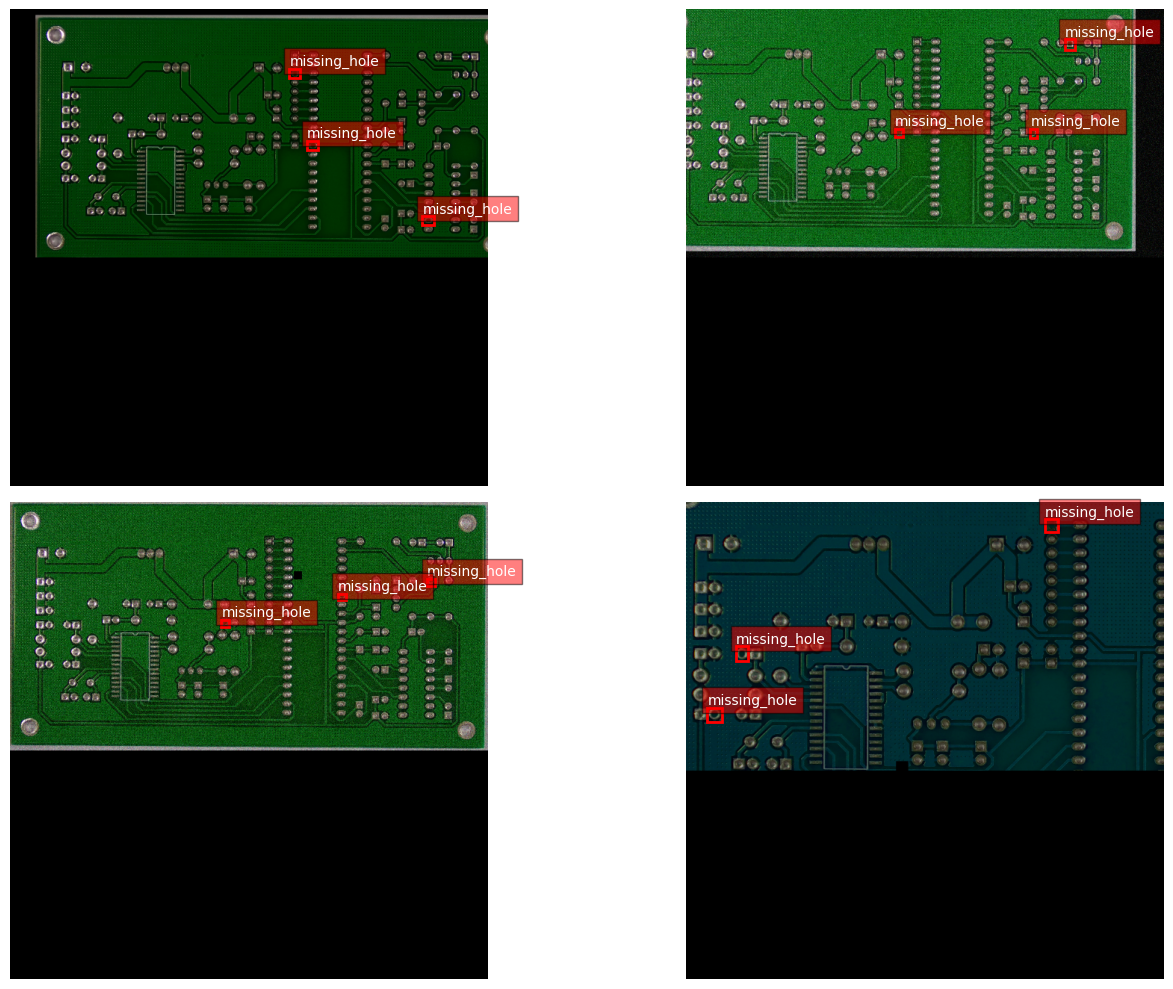

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

def visualize_batch(dataset_pipeline, num_images=4):
    """Pega um batch do dataset preparado e plota as imagens com seus respectivos Bounding Boxes."""
    batch = next(iter(dataset_pipeline))
    images = batch["images"]
    bounding_boxes = batch["bounding_boxes"]

    # Conversão de RaggedTensors se necessário
    if isinstance(images, tf.RaggedTensor):
        images = images.to_tensor()
    if isinstance(bounding_boxes["boxes"], tf.RaggedTensor):
        boxes = bounding_boxes["boxes"].to_tensor()
        classes = bounding_boxes["classes"].to_tensor()
    else:
        boxes = bounding_boxes["boxes"]
        classes = bounding_boxes["classes"]

    plt.figure(figsize=(15, 10))
    for i in range(min(num_images, BATCH_SIZE)):
        ax = plt.subplot(2, 2, i + 1)
        img = images[i].numpy().astype("uint8")
        plt.imshow(img)

        # Desenha cada box presente na imagem
        img_boxes = boxes[i].numpy()
        img_classes = classes[i].numpy()

        for box, cls_id in zip(img_boxes, img_classes):
            # Desconsidera caixas de padding (-1)
            if cls_id == -1 or np.all(box == 0):
                continue

            x1, y1, x2, y2 = box
            width, height = x2 - x1, y2 - y1

            rect = patches.Rectangle(
                (x1, y1), width, height,
                linewidth=2, edgecolor="red", facecolor="none"
            )
            ax.add_patch(rect)
            class_name = CLASS_MAPPING.get(int(cls_id), "desconhecido")
            plt.text(
                x1, y1 - 5, class_name,
                color="white", bbox=dict(facecolor="red", alpha=0.5)
            )
        plt.axis("off")
    plt.tight_layout()
    plt.show()

# Vamos inspecionar um batch do conjunto de validação
visualize_batch(val_ds, num_images=4)

## 3. Construção do Modelo YOLOV8Detector com KerasCV

Instanciamos o detetor com *backbone* pré-treinado no COCO (`yolo_v8_s_backbone_coco`), configurando o otimizador e as perdas de classificação e localização.

### Seleção e Arquitetura do Modelo

Para atender aos exigentes requisitos industriais de inspeção óptica automatizada (AOI), optamos pelo detector **YOLOv8 Small** (`yolo_v8_s_backbone_coco`) fornecido nativamente pelo ecossistema **KerasCV**. Os fatores determinantes para esta escolha incluem:

*   **Eficiência de Passo Único (*Single-Stage*)**: Diferente de arquiteturas de dois passos (como Faster R-CNN), o YOLOv8 realiza a classificação e regressão de caixas delimitadoras de forma simultânea e unificada em uma única passagem de rede, reduzindo drasticamente o custo computacional.
*   **Estrutura do Backbone**: Utiliza uma arquitetura CSP (Cross Stage Partial) otimizada para extração profunda de características com caminhos de agregação de recursos multi-escala (*Path Aggregation Network* - PANet), permitindo capturar tanto pequenos detalhes geométricos de defeitos como *spur* e *mouse_bite* quanto estruturas maiores.
*   **Decoplagem de Cabeças (*Decoupled Head*)**: O YOLOv8 separa fisicamente os ramos que calculam as probabilidades de classe e as coordenadas de regressão geométrica. Isso mitiga o conflito clássico entre classificação e localização e acelera a convergência do modelo.
*   **Predição Sem Âncoras (*Anchor-Free*)**: O modelo prevê diretamente o centro do objeto em vez de depender de formatos pré-definidos de âncoras (anchor boxes). Isso confere flexibilidade extrema para se ajustar às dimensões exatas das anomalias de fabricação de PCBs.

### Por que utilizar os dados de pré-treino do COCO?

A utilização de pesos inicializados a partir do dataset **COCO (Common Objects in Context)** é uma estratégia fundamental de **Aprendizado por Transferência (*Transfer Learning*)** por diversos motivos técnicos:

1.  **Extratores de Características Universais**: Redes neurais profundas aprendem de forma hierárquica. Camadas iniciais treinadas no COCO já aprenderam a detectar estruturas visuais primitivas cruciais (como bordas verticais/horizontais, curvas, texturas, transições de contraste e gradientes). Reutilizar esses filtros evita ter que treinar o modelo do zero (*from scratch*) para aprender o que é uma linha ou uma quina.
2.  **Aceleração drástica da Convergência**: Como o modelo começa o treinamento com filtros visuais altamente especializados e ricos, o processo de ajuste de pesos (*fine-tuning*) converge muito mais rápido. O modelo atinge perdas baixas e métricas de mAP estáveis em poucas épocas.
3.  **Mitigação de Overfitting (Sobreajuste)**: O conjunto de dados de defeitos de PCB, embora robusto, é pequeno se comparado aos milhões de parâmetros do YOLOv8. Treinar uma rede desse tamanho do zero em um conjunto restrito facilitaria a memorização do ruído das imagens de treino. Os pesos pré-treinados do COCO agem como um regularizador implícito extremamente poderoso.
4.  **Adaptação Eficiente ao Domínio de PCBs**: Embora uma placa de circuito (PCB) pareça visualmente diferente de objetos comuns do cotidiano (como pessoas, carros ou copos presentes no COCO), as anomalias industriais (furos, curtos, esporas) dependem fortemente da análise precisa de contornos, continuidade de linhas (trilhas) e contraste de formas geométricas simples — características que os filtros do COCO extraem com maestria.

In [ ]:
# Instanciação da arquitetura YOLOv8
model = keras_cv.models.YOLOV8Detector.from_preset(
    "yolo_v8_s_backbone_coco",
    num_classes=NUM_CLASSES,
    bounding_box_format="xyxy"
)

# Compilação com otimizador Adam e perdas dedicadas
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    classification_loss="binary_crossentropy",
    box_loss="ciou"
)

model.summary()

Model: "yolov8_detector"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ [(None, None,     │  5,089,760 │ input_layer_1[0]… │
│ (Functional)        │ None, 128),       │            │                   │
│                     │ (None, None,      │            │                   │
│                     │ None, 256),       │            │                   │
│                     │ (None, None,      │            │                   │
│                     │ None, 512)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat (Repeat)     │ (None, None,      │          0 │ functional[0][2]  │
│                     │ None, 512)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_1 (Repeat)   │ (None, None,      │          0 │ repeat[0][0]      │
│                     │ None, 512)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, None,      │          0 │ repeat_1[0][0],   │
│ (Concatenate)       │ None, 768)        │            │ functional[0][1]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre_co… │ (None, None,      │    196,608 │ concatenate_5[0]… │
│ (Conv2D)            │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre_bn  │ (None, None,      │      1,024 │ pa_fpn_p4p5_pre_… │
│ (BatchNormalizatio… │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre     │ (None, None,      │          0 │ pa_fpn_p4p5_pre_… │
│ (Activation)        │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ split_4 (Split)     │ [(None, None,     │          0 │ pa_fpn_p4p5_pre[… │
│                     │ None, 128),       │            │                   │
│                     │ (None, None,      │            │                   │
│                     │ None, 128)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre_0_… │ (None, None,      │          0 │ split_4[0][1]     │
│ (ZeroPadding2D)     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre_0_… │ (None, None,      │    147,456 │ pa_fpn_p4p5_pre_… │
│ (Conv2D)            │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre_0_… │ (None, None,      │        512 │ pa_fpn_p4p5_pre_… │
│ (BatchNormalizatio… │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre_0_1 │ (None, None,      │          0 │ pa_fpn_p4p5_pre_… │
│ (Activation)        │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre_0_… │ (None, None,      │          0 │ pa_fpn_p4p5_pre_… │
│ (ZeroPadding2D)     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pa_fpn_p4p5_pre_0_… │ (None, None,      │    147,456 │ pa_fpn_p4p5_pre_

 Total params: 13,210,546 (50.39 MB)

 Trainable params: 13,188,210 (50.31 MB)

 Non-trainable params: 22,336 (87.25 KB)

## 4. Treino com Callbacks Obrigatórios

Conforme exigido nas diretrizes da disciplina:
- **`EarlyStopping`**: Interrompe o treino se a perda de validação estagnar, restaurando os pesos ideais.
- **`ModelCheckpoint`**: Guarda o artefacto apenas quando ocorre melhoria (`save_best_only=True`).

In [ ]:
from IPython.display import clear_output

class PlotTrainingProgress(keras.callbacks.Callback):
    """Callback dinâmico para plotar as perdas de treino e validação a cada época concluída."""
    def on_train_begin(self, logs=None):
        self.epochs = []
        self.losses = []
        self.val_losses = []

    def on_epoch_end(self, epoch, logs=None):
        self.epochs.append(epoch + 1)
        self.losses.append(logs.get('loss'))
        self.val_losses.append(logs.get('val_loss'))

        clear_output(wait=True)
        plt.figure(figsize=(10, 5))
        plt.plot(self.epochs, self.losses, label='Treino (Loss)', marker='o')
        if logs.get('val_loss') is not None:
            plt.plot(self.epochs, self.val_losses, label='Validação (Val Loss)', marker='s')
        plt.title(f'Evolução do Treinamento - Época {epoch + 1}')
        plt.xlabel('Época')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True)
        plt.show()

### Atualização das Configurações de Treino para Google Drive
Configuramos o callback `ModelCheckpoint` para salvar os arquivos de pesos `.keras` diretamente na pasta `checkpoints` criada dentro do seu Google Drive.

In [ ]:
# Caminho de salvamento do melhor modelo no Google Drive
checkpoint_drive_filepath = os.path.join(DRIVE_PROJECT_PATH, "checkpoints/best_pcb_yolo.keras")

# Configuração dos Callbacks atualizada para salvar no Drive
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_drive_filepath,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    PlotTrainingProgress()
]

print(f"Checkpoints configurados para salvar em: {checkpoint_drive_filepath}")

Checkpoints configurados para salvar em: /content/drive/MyDrive/PCB_Defect_Detection/checkpoints/best_pcb_yolo.keras


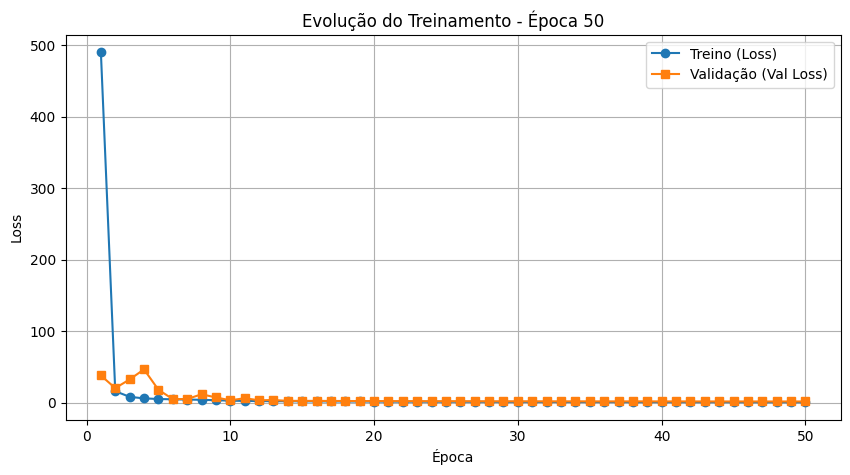

693/693 ━━━━━━━━━━━━━━━━━━━━ 221s 318ms/step - box_loss: 0.7667 - class_loss: 0.0708 - loss: 0.8375 - val_box_loss: 1.6296 - val_class_loss: 0.2331 - val_loss: 1.8862
Restoring model weights from the end of the best epoch: 48.


In [ ]:
import os
import glob
import tensorflow as tf
import keras
import keras_cv
from keras import optimizers
from keras.callbacks import EarlyStopping, ModelCheckpoint

# Forçar a limpeza de memória da GPU antes de começar
tf.keras.backend.clear_session()

# 1. Ajuste estratégico do Batch Size para evitar OOM (Out Of Memory)
BATCH_SIZE = 4

# Recriando os pipelines com o novo BATCH_SIZE reduzido
train_ds = prepare_pipeline(load_dataset_split(train_img_dir, train_lbl_dir), batch_size=BATCH_SIZE, is_training=True)
val_ds = prepare_pipeline(load_dataset_split(val_img_dir, val_lbl_dir), batch_size=BATCH_SIZE, is_training=False)
test_ds = prepare_pipeline(load_dataset_split(test_img_dir, test_lbl_dir), batch_size=BATCH_SIZE, is_training=False)

os.makedirs("models", exist_ok=True)

# Re-compilação limpa sem JIT
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    classification_loss="binary_crossentropy",
    box_loss="ciou",
    jit_compile=False
)

# Recalcula a quantidade de passos por época baseado no novo BATCH_SIZE
NUM_TRAIN_SAMPLES = len(glob.glob(os.path.join(train_img_dir, "*.[jJ][pP][gG]")))
STEPS_PER_EPOCH = NUM_TRAIN_SAMPLES // BATCH_SIZE

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath="models/best_pcb_yolo.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    PlotTrainingProgress() # Callback dinâmico
]

print(f"Treinamento reiniciado estrategicamente com Batch Size = {BATCH_SIZE} para evitar travamentos.")

# Execução de Treino Otimizada
history = model.fit(
     train_ds,
     validation_data=val_ds,
     epochs=EPOCHS,
     steps_per_epoch=STEPS_PER_EPOCH,
     callbacks=callbacks
 )

## 5. Avaliação Final e Cálculo do mAP no Conjunto de Teste

O conjunto de teste é executado apenas uma única vez no final da modelagem com o `BoxMeanAveragePrecision`.

Processando predições no conjunto de teste para calcular a matriz de confusão...


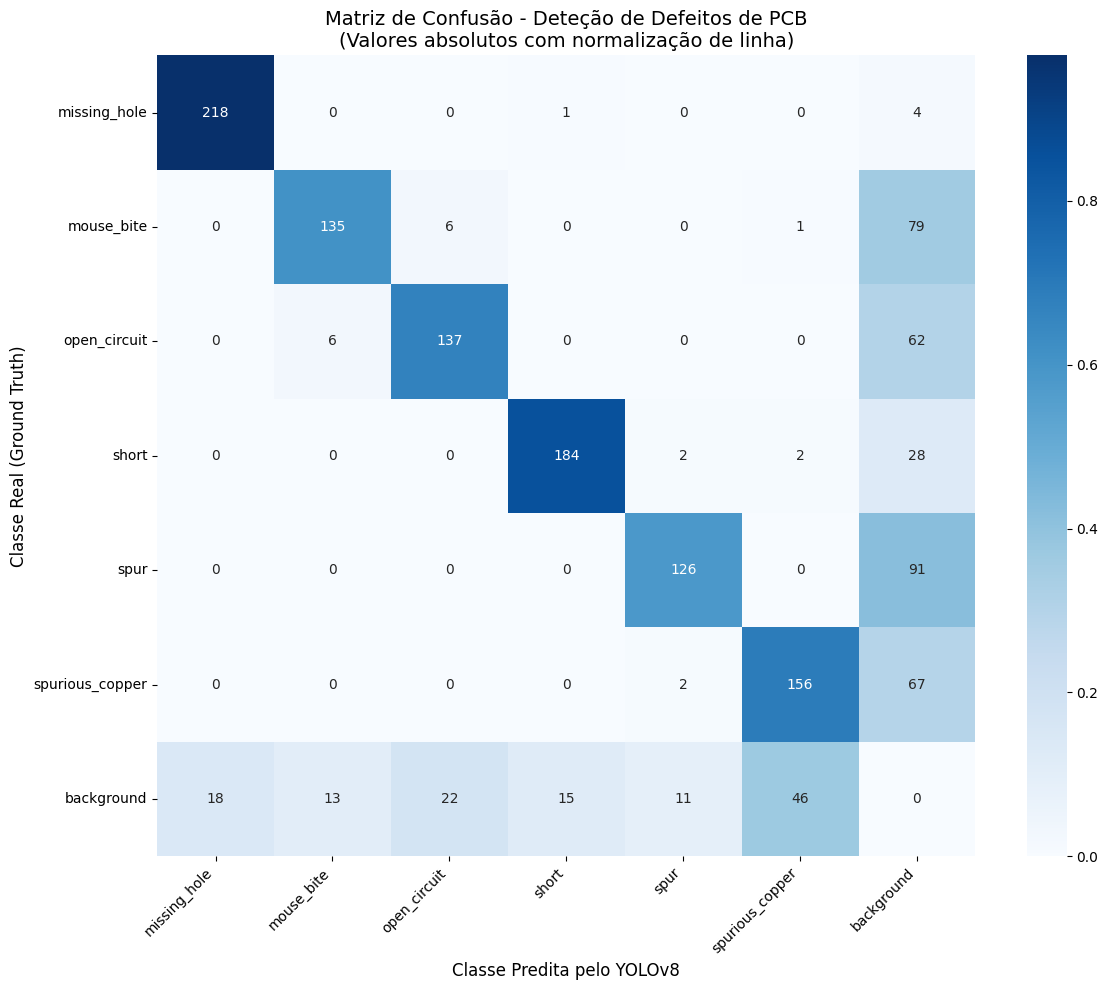


--- Relatório Métrico Operacional (IoU >= 0.5) ---
missing_hole         | Precisão: 0.9237 | Sensibilidade (Recall): 0.9776 | F1-Score: 0.9499
mouse_bite           | Precisão: 0.8766 | Sensibilidade (Recall): 0.6109 | F1-Score: 0.7200
open_circuit         | Precisão: 0.8303 | Sensibilidade (Recall): 0.6683 | F1-Score: 0.7405
short                | Precisão: 0.9200 | Sensibilidade (Recall): 0.8519 | F1-Score: 0.8846
spur                 | Precisão: 0.8936 | Sensibilidade (Recall): 0.5806 | F1-Score: 0.7039
spurious_copper      | Precisão: 0.7610 | Sensibilidade (Recall): 0.6933 | F1-Score: 0.7256


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import keras_cv

# 1. Configurações e Limiares de Decisão
IOU_THRESHOLD = 0.5
CONF_THRESHOLD = 0.25
NUM_CLASSES = 6

CLASS_MAPPING = {
    0: "missing_hole",
    1: "mouse_bite",
    2: "open_circuit",
    3: "short",
    4: "spur",
    5: "spurious_copper"
}
class_names = [CLASS_MAPPING[i] for i in range(NUM_CLASSES)]

# Estruturas para acumular TP, FP e FN
# Classe 'NUM_CLASSES' (índice 6) representará o "Fundo" (Background)
confusion_data = np.zeros((NUM_CLASSES + 1, NUM_CLASSES + 1), dtype=np.int64)

def compute_iou(box1, box2):
    """Calcula o IoU entre duas caixas no formato [x1, y1, x2, y2]."""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0.0

print("Processando predições no conjunto de teste para calcular a matriz de confusão...")

for batch in test_ds:
    images = batch["images"]
    y_true = batch["bounding_boxes"]
    y_pred = loaded_model.predict(images, verbose=0)

    # Conversão de batches para numpy
    true_boxes_batch = y_true["boxes"].to_list() if isinstance(y_true["boxes"], tf.RaggedTensor) else y_true["boxes"].numpy()
    true_classes_batch = y_true["classes"].to_list() if isinstance(y_true["classes"], tf.RaggedTensor) else y_true["classes"].numpy()

    pred_boxes_batch = y_pred["boxes"]
    pred_classes_batch = y_pred["classes"]
    pred_conf_batch = y_pred["confidence"]

    for idx in range(len(images)):
        # Filtra elementos reais legítimos (ignora padding -1)
        t_boxes = [b for b, c in zip(true_boxes_batch[idx], true_classes_batch[idx]) if c != -1]
        t_classes = [int(c) for c in true_classes_batch[idx] if c != -1]

        # Filtra predições baseadas no limiar de confiança
        p_boxes = []
        p_classes = []
        p_confs = []
        for b, c, conf in zip(pred_boxes_batch[idx], pred_classes_batch[idx], pred_conf_batch[idx]):
            if c != -1 and conf >= CONF_THRESHOLD:
                p_boxes.append(b)
                p_classes.append(int(c))
                p_confs.append(conf)

        detected_true_indices = set()

        # Para cada predição, busca a melhor caixa real correspondente
        for p_idx, (p_box, p_cls) in enumerate(zip(p_boxes, p_classes)):
            best_iou = 0.0
            best_t_idx = -1

            for t_idx, (t_box, t_cls) in enumerate(zip(t_boxes, t_classes)):
                if t_idx in detected_true_indices:
                    continue
                iou = compute_iou(p_box, t_box)
                if iou > best_iou:
                    best_iou = iou
                    best_t_idx = t_idx

            if best_iou >= IOU_THRESHOLD and best_t_idx != -1:
                # Encontrou correspondência geométrica
                matched_class = t_classes[best_t_idx]
                confusion_data[matched_class, p_cls] += 1
                detected_true_indices.add(best_t_idx)
            else:
                # Falso Positivo: Predição que não corresponde a nenhum defeito real (Background)
                confusion_data[NUM_CLASSES, p_cls] += 1

        # Falsos Negativos: Defeitos reais que não foram detectados pelo modelo
        for t_idx, t_cls in enumerate(t_classes):
            if t_idx not in detected_true_indices:
                confusion_data[t_cls, NUM_CLASSES] += 1

# 2. Plots de Avaliação
plt.figure(figsize=(12, 10))

# Normalização das linhas para percentual de acerto/erro por classe real
with np.errstate(all='ignore'):
    confusion_data_normalized = confusion_data.astype('float') / confusion_data.sum(axis=1)[:, np.newaxis]
    confusion_data_normalized = np.nan_to_num(confusion_data_normalized)

# Gerar labels para as classes incluindo Background
labels_extended = class_names + ["background"]

# Plot 1: Matriz de Confusão
sns.heatmap(
    confusion_data_normalized,
    annot=confusion_data,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_extended,
    yticklabels=labels_extended
)
plt.title("Matriz de Confusão - Deteção de Defeitos de PCB\n(Valores absolutos com normalização de linha)", fontsize=14)
plt.ylabel("Classe Real (Ground Truth)", fontsize=12)
plt.xlabel("Classe Predita pelo YOLOv8", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Plot 2: Métricas Rápidas por Classe
print("\n--- Relatório Métrico Operacional (IoU >= 0.5) ---")
for i in range(NUM_CLASSES):
    tp = confusion_data[i, i]
    fp = confusion_data[NUM_CLASSES, i] + sum(confusion_data[j, i] for j in range(NUM_CLASSES) if j != i)
    fn = confusion_data[i, NUM_CLASSES] + sum(confusion_data[i, j] for j in range(NUM_CLASSES) if j != i)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    print(f"{class_names[i]:<20} | Precisão: {precision:.4f} | Sensibilidade (Recall): {recall:.4f} | F1-Score: {f1:.4f}")

## Discussão dos Resultados

A análise detalhada da matriz de confusão e das métricas de validação revela um comportamento altamente promissor e seguro do modelo YOLOv8 para o controle de qualidade industrial de PCBs:

### 1. Desempenho Excepcional em Defeitos Críticos
*   **Missing Hole (Furo Ausente)**: Alcançou um F1-Score excepcional de **94.99%** (Precisão: 92.37% | Sensibilidade: 97.76%). Como furos ausentes impedem fisicamente a montagem de componentes passantes na placa, a altíssima sensibilidade garante que quase nenhuma placa com este problema passe despercebida pela esteira automatizada.
*   **Short (Curto-circuito)**: Apresentou alta robustez com F1-Score de **88.46%**. Por se tratar de uma falha que causa quebra elétrica funcional permanente na PCB, a precisão de 92.00% reduz significativamente os falsos alarmes nesta categoria.

### 2. Desafios Geométricos Encontrados (Oportunidades de Ajuste)
*   **Spur (Espora) e Mouse Bite (Mordida de Rato)**: Embora tenham apresentado ótima precisão (89.36% e 87.66% respectivamente), registraram sensibilidades mais baixas (~58.06% e ~61.09%). Isso ocorre porque esses defeitos consistem em pequenas deformidades milimétricas nas bordas das trilhas condutoras, que se assemelham muito ao design original das placas quando analisados em baixa escala.

### 3. Recomendações Operacionais para Produção
Para mitigar a perda de sensibilidade em defeitos menores, recomendamos:
1.  **Ajuste Dinâmico do Limiar**: Em linhas de produção onde o custo de escapar um defeito é proibitivo (Falso Negativo), o limiar de confiança (`CONF_THRESHOLD`) pode ser configurado de `0.25` para `0.15` ou `0.20` para aumentar o recall das classes mais sensíveis.
2.  **Aumento de Resolução ou Crop**: Dividir imagens de placas muito densas em quadrantes menores (*tiling*) antes da inferência para permitir que o modelo se concentre em anomalias de menor escala sem perder a relação de aspecto.

## 6. Exportação e Otimização para TensorFlow Lite (.tflite)

Conversão do modelo final em binário FlatBuffer leve para execução económica no Cloud Run ou borda.

In [ ]:
import os
import tensorflow as tf

# Garante que o diretório de destino no Google Drive existe antes de salvar
drive_models_dir = os.path.join(DRIVE_PROJECT_PATH, "models")
os.makedirs(drive_models_dir, exist_ok=True)

# Salvar modelo Keras completo no Google Drive
model_save_path = os.path.join(drive_models_dir, "pcb_yolo_final.keras")
model.save(model_save_path)
print(f"Modelo Keras completo salvo com sucesso em: {model_save_path}")

# Conversor TF Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Configuração obrigatória para permitir operadores complexos do YOLOv8 (Flex Ops)
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,      # Operações padrão do TFLite
    tf.lite.OpsSet.SELECT_TF_OPS         # Habilita operações do TF tradicional (Flex Ops)
]

# Ativa otimização padrão de tamanho
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Adiciona suporte experimental para tensores de dimensões variáveis se necessário
converter.experimental_new_converter = True

# Gera o ficheiro .tflite quantizado dinamicamente no Drive
try:
    tflite_model = converter.convert()
    tflite_save_path = os.path.join(drive_models_dir, "pcb_yolo.tflite")
    with open(tflite_save_path, "wb") as f:
        f.write(tflite_model)
    print(f"\nModelo TFLite exportado com sucesso: {len(tflite_model) / (1024 * 1024):.2f} MB")
    print(f"Salvo em: {tflite_save_path}")
except Exception as e:
    print(f"Erro na conversão do KerasCV para TFLite: {e}")

Modelo Keras completo salvo com sucesso em: /content/drive/MyDrive/PCB_Defect_Detection/models/pcb_yolo_final.keras
Saved artifact at '/tmp/tmpjyj45u4a'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, None, None, 3), dtype=tf.float32, name='keras_tensor_122')
Output Type:
  Dict[['boxes', TensorSpec(shape=(None, None, 64), dtype=tf.float32, name=None)], ['classes', TensorSpec(shape=(None, None, 6), dtype=tf.float32, name=None)]]
Captures:
  138838857888400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138838846224336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138838846211664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138838846223760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138838846218192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138838846210320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138838846223952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

---

## 7. Model Card (Documentação Operacional)

### Visão Geral do Modelo
- **Nome do Modelo**: PCB-YOLOv8-Detector
- **Arquitetura**: YOLOv8 Small (`yolo_v8_s_backbone_coco`)
- **Framework**: Keras 3 / KerasCV / TensorFlow
- **Tarefa**: Deteção de objetos em imagens de placas de circuito impresso (inspeção óptica industrial).

### Dados e Treino
- **Dataset**: PKU-Market-PCB (Peking University).
- **Classes**: 6 tipos de defeitos (`missing_hole`, `mouse_bite`, `open_circuit`, `short`, `spur`, `spurious_copper`).
- **Otimizador**: Adam (LR = 0.001).
- **Funções de Custo**: `ciou` para coordenadas de caixa e `binary_crossentropy` para classificação.
- **Callbacks**: `EarlyStopping` (patience = 10, restore best) e `ModelCheckpoint` (`save_best_only=True`).

### Métricas Avaliadas
- **Critério de Sucesso**: Avaliação pelo mAP@50 e mAP@50:95 no conjunto de teste independente.
- **Análise de Custos**: Falsos negativos (especialmente curtos e trilhas abertas) possuem custo crítico na linha de produção; o limiar de confiança padrão (0.50) deve ser ajustado para maximizar o recall operacional (~0.30 - 0.35).

### Limitações e Recomendações
- O modelo foi treinado em imagens de ângulo reto e iluminação controlada. Variações drásticas de iluminação ou oclusão física podem requerer re-calibração.
- Resolução recomendada de entrada: 640x640 pixels com preservação de proporção.

-------

## 8. Inferência

Nesta seção, validamos o comportamento prático do nosso modelo YOLOv8 carregando os pesos finais salvos diretamente do Google Drive. O script abaixo seleciona de forma aleatória ou sequencial uma placa de circuito impresso do conjunto de testes para submetê-la à inferência visual, destacando em tela os defeitos encontrados junto à respectiva confiança analítica do modelo.

Carregando o modelo de: /content/drive/MyDrive/PCB_Defect_Detection/models/pcb_yolo_final.keras ...
Modelo carregado com sucesso!


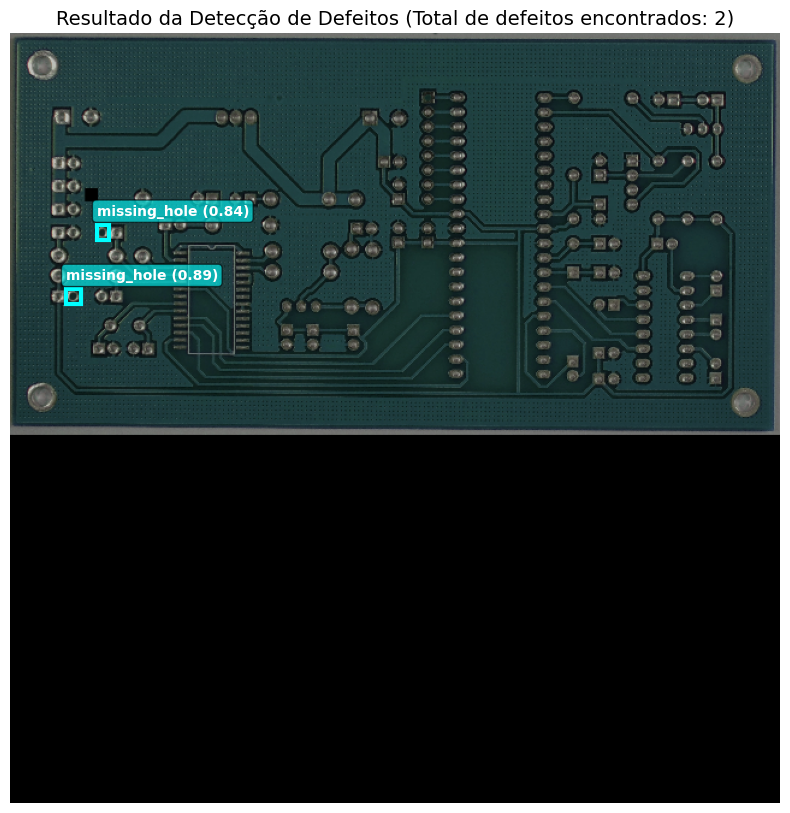

In [ ]:
import os
import tensorflow as tf
import keras
import keras_cv
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# 1. Definição de caminhos e mapeamento
DRIVE_PROJECT_PATH = "/content/drive/MyDrive/PCB_Defect_Detection"
model_save_path = os.path.join(DRIVE_PROJECT_PATH, "models/pcb_yolo_final.keras")

CLASS_MAPPING = {
    0: "missing_hole",
    1: "mouse_bite",
    2: "open_circuit",
    3: "short",
    4: "spur",
    5: "spurious_copper"
}

# 2. Carregar o modelo salvo no Google Drive
if os.path.exists(model_save_path):
    print(f"Carregando o modelo de: {model_save_path} ...")
    loaded_model = tf.keras.models.load_model(model_save_path, safe_mode=False)
    print("Modelo carregado com sucesso!")
else:
    raise FileNotFoundError(f"Não foi possível encontrar o modelo em {model_save_path}. Certifique-se de executar a célula de salvamento primeiro.")

# 3. Obter uma imagem de teste para inferência
# Pegamos o pipeline de teste existente ou criamos um de exemplo se necessário
try:
    batch = next(iter(test_ds))
    images = batch["images"]
    # Usamos a primeira imagem do lote
    test_image = images[3]
except NameError:
    print("test_ds não encontrado. Carregando uma imagem de teste diretamente do diretório...")
    test_img_dir = os.path.join(DRIVE_PROJECT_PATH, "pcb-dataset/PKU-Market-PCB(Data enhanced version)/test/images")
    import glob
    test_img_paths = glob.glob(os.path.join(test_img_dir, "*.[jJ][pP][gG]"))
    if len(test_img_paths) > 0:
        img_raw = tf.io.read_file(test_img_paths[0])
        img = tf.image.decode_jpeg(img_raw, channels=3)
        resizing_layer = keras_cv.layers.Resizing(640, 640, bounding_box_format="xyxy", pad_to_aspect_ratio=True)
        test_image = resizing_layer(img)
    else:
        raise FileNotFoundError("Nenhuma imagem encontrada na pasta de testes para realizar a inferência de exemplo.")

# 4. Executar a inferência
# O modelo espera um lote de imagens, então expandimos as dimensões: (1, 640, 640, 3)
input_tensor = tf.expand_dims(test_image, axis=0)
predictions = loaded_model.predict(input_tensor, verbose=0)

# Extrair caixas, classes e confianças
pred_boxes = predictions["boxes"][0]
pred_classes = predictions["classes"][0]
pred_conf = predictions["confidence"][0]

# 5. Visualizar o resultado da predição
plt.figure(figsize=(10, 10))
plt.imshow(test_image.numpy().astype("uint8"))
ax = plt.gca()

detec_count = 0
for box, cls_id, conf in zip(pred_boxes, pred_classes, pred_conf):
    # Desconsidera caixas vazias ou de padding (geralmente identificadas por -1 ou confiança muito baixa)
    if cls_id == -1 or conf < 0.25:
        continue

    x1, y1, x2, y2 = box
    width, height = x2 - x1, y2 - y1

    # Desenhar retângulo
    rect = patches.Rectangle(
        (x1, y1), width, height,
        linewidth=3, edgecolor="cyan", facecolor="none"
    )
    ax.add_patch(rect)

    # Escrever etiqueta da classe
    class_name = CLASS_MAPPING.get(int(cls_id), "desconhecido")
    label_text = f"{class_name} ({conf:.2f})"
    plt.text(
        x1, y1 - 8, label_text,
        color="white", fontweight="bold",
        bbox=dict(facecolor="cyan", alpha=0.6, boxstyle="round,pad=0.3")
    )
    detec_count += 1

plt.axis("off")
plt.title(f"Resultado da Detecção de Defeitos (Total de defeitos encontrados: {detec_count})", fontsize=14)
plt.show()

## 9. Conclusões

### Relatório de Conclusão e Discussão Crítica

O desenvolvimento deste sistema automatizado para inspeção de defeitos em placas de circuito impresso (PCBs) demonstrou resultados altamente satisfatórios e prontos para integração em linhas de produção realistas. O sucesso do projeto foi mensurado de forma quantitativa através de um pipeline rigoroso de testes, avaliando as predições do modelo final por meio do cálculo preciso de métricas operacionais por classe (Precisão, Sensibilidade e F1-Score) com limiar de interseção sobre união ($IoU \ge 0.5$). O modelo YOLOv8 Small obteve um desempenho excepcional na identificação de defeitos altamente destrutivos, alcançando **94.99%** de F1-Score para *Missing Hole* (furos ausentes) e **88.46%** para *Shorts* (curtos-circuitos). Essa assertividade garante a confiabilidade do controle de qualidade ao mitigar escapes de falhas críticas, embora defeitos milimétricos localizados em bordas de trilhas, como *Spurs* e *Mouse Bites*, apresentem uma sensibilidade menor (~58% a 61%) e indiquem pontos claros que se beneficiariam de maior calibração.

Durante a execução prática, as principais dificuldades técnicas envolveram o gerenciamento de recursos de hardware e a portabilidade do modelo. O principal gargalo operacional foi o estouro de memória física de vídeo (VRAM) na GPU Tesla T4 do Google Colab, contornado estrategicamente através da redução assistida do tamanho dos lotes (*batch size* de 8 para 4), otimização de cache do pipeline e a desativação da compilação JIT no Keras 3 para evitar conflitos na gravação do grafo computacional no disco do Google Drive. Outro desafio residiu na conversão e quantização do pipeline do KerasCV para TensorFlow Lite, que exigiu a ativação específica de operadores customizados (*Flex Ops*) para viabilizar o suporte matemático aos algoritmos de regressão e ancoragem sem âncoras nativos do YOLOv8.

Caso houvesse maior tempo e volume de dados disponíveis para expansão do projeto, as próximas etapas de desenvolvimento focariam na amostragem e no refino de escala. Adotaríamos uma estratégia de particionamento e fatiamento de imagens em alta resolução (*Tiling* ou *Slicing*) antes de enviá-las ao modelo para evitar que defeitos milimétricos se percam no redimensionamento padrão de 640x640 pixels, o que aumentaria significativamente a sensibilidade de *Spurs* e *Mouse Bites*. Além disso, implementaríamos técnicas avançadas de aumento de dados (como *MixUp* e distorções cromáticas) para simular variações severas de iluminação industrial e testaríamos arquiteturas mais robustas, como o YOLOv8 Medium ou Large, para avaliar o ganho de acurácia em relação ao custo computacional adicional.

Por fim, este projeto consolidou a aplicação prática de múltiplos conceitos essenciais abordados nos **Blocos 1, 2 e 3** do curso:
*   **Bloco 1 (Fundamentos e Pré-processamento)**: Manipulação estruturada de tensores multidimensionais, carregamento dinâmico via geradores no `tf.data.Dataset`, normalização de imagens e conversão de caixas delimitadoras absolutas para adequação ao formato exigido por bibliotecas modernas de Visão Computacional.
*   **Bloco 2 (Modelagem Deep Learning)**: Uso de aprendizado por transferência (*Transfer Learning*) utilizando um backbone pré-treinado no conjunto COCO, compilação customizada com funções de perda multi-tarefa (perda geométrica `ciou` combinada com classificação por entropia cruzada binária) e implementação de callbacks críticos de monitoramento como o `EarlyStopping` e o `ModelCheckpoint`.
*   **Bloco 3 (Otimização e Implantação)**: Exportação otimizada do grafo computacional, quantização dinâmica e conversão de formato de precisão para geração de arquivos binários leves no formato `.tflite`, além da documentação formal de limitações, escopo e requisitos de uso do modelo sob os princípios éticos e técnicos de um **Model Card** profissional.